In [1]:
from vistiq.io import ImageLoader, ImageLoaderConfig, ImageWriter, ImageWriterConfig
from vistiq.utils import check_device, ArrayIteratorConfig
from vistiq.preprocess import PreprocessFlowConfig, FuncProcessorConfig, PeriodicDenoise, PeriodicDenoiseConfig
from vistiq.segment import MicroSAMSegmenterConfig, MicroSAMSegmenter, SegmentationFlowConfig, SegmentationFlow
from vistiq.segment import RegionFilterConfig, RegionFilter
from vistiq.analysis import RegionAnalyzerConfig, RegionAnalyzer

import logging
import stackview
import numpy as np

# Configure logger and check availability of accelerator

In [2]:
import vistiq
logger = logging.getLogger(vistiq.__name__)

logger.info(f"Available Torch accelerators: {check_device()}")

2026-10-09 00:27:01,349 - INFO - Found cuda device: NVIDIA RTX PRO 6000 Blackwell Server Edition MIG 1g.24gb
2026-10-09 00:27:01,350 - INFO - Available Torch accelerators: cuda:0


# Load image

In [3]:
data_dir = "/project/skyrmion/data/"
fname = f"{data_dir}/2026-07-22-patches/Camera Ceta 1149 0001 Ceta.tif"
# fname = f"{data_dir}/Si3N4_0001_multislice.emd"

ch = 1
icfg = ImageLoaderConfig(squeeze=True, substack=f"S:{ch}", rename_channel={"Channel:0:0":f"channel {ch}"})

img, metadata = ImageLoader(icfg).run(fname)
display(metadata)

2026-10-09 00:27:01,595 - INFO - HTTP Request: GET https://api.prefect.cloud/api/accounts/fe04c388-039f-4a9a-8a38-6ddd01791c77/workspaces/0aefefee-2869-4637-89ac-c510d86c639e/admin/storage "HTTP/1.1 404 Not Found"
2026-10-09 00:27:01,650 - INFO - HTTP Request: GET https://api.prefect.cloud/api/accounts/fe04c388-039f-4a9a-8a38-6ddd01791c77/workspaces/0aefefee-2869-4637-89ac-c510d86c639e/admin/storage "HTTP/1.1 404 Not Found"
2026-10-09 00:27:01,655 - INFO - Loading image from: /project/skyrmion/data/2026-07-22-patches/Camera Ceta 1149 0001 Ceta.tif
2026-10-09 00:27:01,753 - WARNING - Attempted file (/project/skyrmion/data/2026-07-22-patches/Camera Ceta 1149 0001 Ceta.tif) load with reader: <class 'bioio_ome_tiff.reader.Reader'> failed with error: bioio-ome-tiff does not support the image: '/project/skyrmion/data/2026-07-22-patches/Camera Ceta 1149 0001 Ceta.tif'. Failed to parse XML for the provided file. Error: no element found: line 1, column 0
2026-10-09 00:27:01,756 - INFO - Scenes 

{'scene_index': None,
 'dim_order': 'YX',
 'axes': ['Y', 'X'],
 'channel_names': ['channel 1'],
 'channel_axis': None,
 'shape': (4096, 4096),
 'dims': <Dimensions [Y: 4096, X: 4096]>,
 'pixel_unit': 'um',
 'scale': Scale(T=None, C=None, Z=None, Y=None, X=None),
 'physical_pixel_sizes': PhysicalPixelSizes(Z=None, Y=None, X=None)}

[[ 38  38  38 ...   0   0   0]
 [ 53  53  53 ...   0   0   0]
 [ 58  58  58 ...   0   0   0]
 ...
 [ 68  68  68 ... 109 102 113]
 [ 64  64  64 ... 104 108 117]
 [ 68  68  68 ... 115 111 120]]
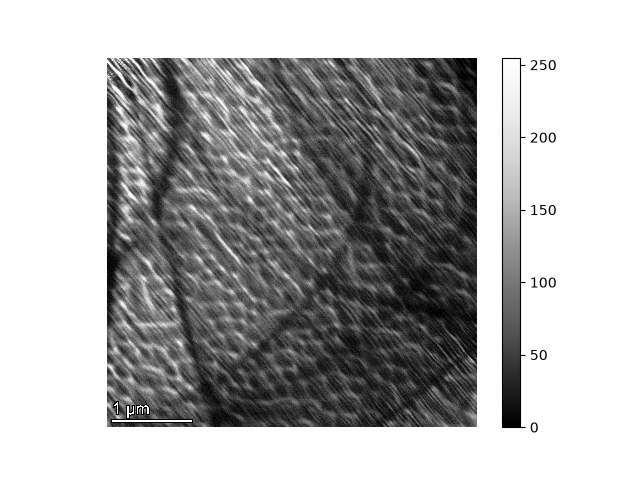
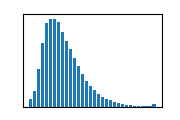

In [20]:
stackview.insight(img)

# Preprocess

In [5]:
pdcfg = PeriodicDenoiseConfig(
    min_distance=50,
    threshold=0.001,
    radius=15,
    mask_angle=[139.0],
    angle_tolerance=1.0,
    mode="degree",
    iterator_config=ArrayIteratorConfig(slice_def=(-2, -1)),
)

denoised,_ = PeriodicDenoise(pdcfg).run(img, metadata=metadata)

2026-10-09 00:27:02,123 - INFO - HTTP Request: GET https://api.prefect.cloud/api/accounts/fe04c388-039f-4a9a-8a38-6ddd01791c77/workspaces/0aefefee-2869-4637-89ac-c510d86c639e/admin/storage "HTTP/1.1 404 Not Found"
2026-10-09 00:27:02,156 - INFO - HTTP Request: GET https://api.prefect.cloud/api/accounts/fe04c388-039f-4a9a-8a38-6ddd01791c77/workspaces/0aefefee-2869-4637-89ac-c510d86c639e/admin/storage "HTTP/1.1 404 Not Found"
2026-10-09 00:27:02,182 - INFO - Running preprocessor PeriodicDenoise, on stack of type uint8, True
2026-10-09 00:27:02,207 - INFO - Running PeriodicDenoise with config: classname='vistiq.core.Configurable' package='vistiq.core' version=None command_group=None iterator_config=ArrayIteratorConfig(classname=None, slice_def=(-2, -1)) batch_size=10 preferred_backend='threads' tile_shape=None output_type='stack' output_shape=None output_axes=None recompute_scale=False squeeze=True split_axis=None split_channels=False rename_channel=None normalize=False dtype=None min_dis

In [6]:
stackview.curtain(img, denoised, continuous_update=False)

# Segment

In [7]:
embedding_path = "/project/skyrmion/embeddings"

mcfg = MicroSAMSegmenterConfig(
    model_type="vit_l_lm", # "vit_l_em_organelles", # 
    embedding_path=embedding_path,
    iterator_config=ArrayIteratorConfig(slice_def=()),
)

scfg = SegmentationFlowConfig(
    segmenter=mcfg,
)

labels = SegmentationFlow(scfg).run(img, metadata=metadata)
labels_denoised = SegmentationFlow(scfg).run(denoised, metadata=metadata)

2026-10-09 00:27:04,190 - INFO - HTTP Request: POST https://api.prefect.cloud/api/accounts/fe04c388-039f-4a9a-8a38-6ddd01791c77/workspaces/0aefefee-2869-4637-89ac-c510d86c639e/flows/ "HTTP/1.1 200 OK"
2026-10-09 00:27:04,267 - INFO - HTTP Request: POST https://api.prefect.cloud/api/accounts/fe04c388-039f-4a9a-8a38-6ddd01791c77/workspaces/0aefefee-2869-4637-89ac-c510d86c639e/flow_runs/ "HTTP/1.1 201 Created"
2026-10-09 00:27:04,310 - INFO - HTTP Request: GET https://api.prefect.cloud/api/accounts/fe04c388-039f-4a9a-8a38-6ddd01791c77/workspaces/0aefefee-2869-4637-89ac-c510d86c639e/admin/storage "HTTP/1.1 404 Not Found"
2026-10-09 00:27:04,389 - INFO - HTTP Request: PATCH https://api.prefect.cloud/api/accounts/fe04c388-039f-4a9a-8a38-6ddd01791c77/workspaces/0aefefee-2869-4637-89ac-c510d86c639e/flow_runs/06ac86d1-83cb-7414-8000-00be8a85c85f "HTTP/1.1 204 No Content"
2026-10-09 00:27:04,475 - INFO - HTTP Request: POST https://api.prefect.cloud/api/accounts/fe04c388-039f-4a9a-8a38-6ddd01791c

[[0.27242237 0.2761493  0.27891073 ... 0.12273747 0.12955266 0.13532136]
 [0.3239103  0.32851812 0.33210489 ... 0.11910988 0.12690374 0.13363244]
 [0.33973232 0.34528059 0.34975934 ... 0.11453594 0.12333369 0.13106094]
 ...
 [0.37492907 0.37641171 0.37711558 ... 0.50809598 0.4878433  0.52936262]
 [0.36229962 0.36446178 0.36578178 ... 0.48960111 0.50850987 0.54385912]
 [0.37692252 0.37983319 0.38183871 ... 0.52604622 0.51798546 0.55419201]]
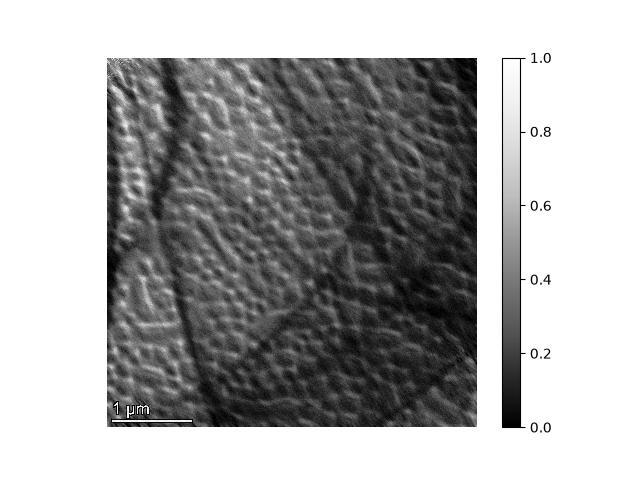
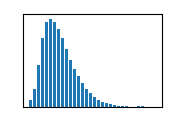

In [19]:
stackview.insight(denoised)#, labels_denoised, continuous_update=False)
#img.dtype, denoised.dtype, labels.dtype, labels_denoised.dtype

# Analyze regions

In [9]:
display(metadata["axes"])
if all([s is None for s in metadata["scale"]]): 
    # in case scale is not set
    metadata["scale"] = tuple([1 for _ in metadata["axes"]])
display(f"scale: {metadata['scale']}")

racfg = RegionAnalyzerConfig(
    output_type="dataframe",
    properties = ["centroid", "area", "circularity", "eccentricity"],
    map_axes = True,
)
ra = RegionAnalyzer(racfg)
results = ra.run(labels_denoised, metadata=metadata)

display(results)

['Y', 'X']

'scale: (1, 1)'

2026-10-09 00:27:17,642 - INFO - HTTP Request: GET https://api.prefect.cloud/api/accounts/fe04c388-039f-4a9a-8a38-6ddd01791c77/workspaces/0aefefee-2869-4637-89ac-c510d86c639e/admin/storage "HTTP/1.1 404 Not Found"
2026-10-09 00:27:17,684 - INFO - HTTP Request: GET https://api.prefect.cloud/api/accounts/fe04c388-039f-4a9a-8a38-6ddd01791c77/workspaces/0aefefee-2869-4637-89ac-c510d86c639e/admin/storage "HTTP/1.1 404 Not Found"
2026-10-09 00:27:17,951 - INFO - Running RegionAnalyzer with config: classname='vistiq.core.Configurable' package='vistiq.core' version=None command_group=None iterator_config=ArrayIteratorConfig(classname=None, slice_def=(-2, -1)) batch_size=10 preferred_backend='threads' tile_shape=None output_type='dataframe' output_shape=None output_axes=None recompute_scale=False squeeze=True split_axis=None split_channels=False rename_channel=None index_on='label' properties=['label', 'stack_id', 'slice_id', 'object_id', 'centroid', 'area', 'circularity', 'eccentricity'] map_a

,centroid-y,centroid-x,area,eccentricity,circularity,channel,object_id,stack_id,slice_id,object_name
label,,,,,,,,,,
1,115.590215,2037.226666,11528.0,0.757752,0.640092,channel 1,40e49d6cf5894e19a1b72bb791169d06,90ecd7b6da684775b4f36f4dd0441c7c,3865877f97fb4b1eafd24350b5d093fd,channel 1 1
2,188.423399,2354.180034,20274.0,0.900423,0.696816,channel 1,0b733c452c974995b95fdd7cf6476da2,90ecd7b6da684775b4f36f4dd0441c7c,3865877f97fb4b1eafd24350b5d093fd,channel 1 2
3,148.667137,1643.262341,2836.0,0.960143,0.429221,channel 1,3706ea4eeb6f4d228bc34c19a2c84642,90ecd7b6da684775b4f36f4dd0441c7c,3865877f97fb4b1eafd24350b5d093fd,channel 1 3
4,202.170430,2630.936923,11383.0,0.751673,0.805891,channel 1,b2fd8484354a4fd58c3ee6a35a46622a,90ecd7b6da684775b4f36f4dd0441c7c,3865877f97fb4b1eafd24350b5d093fd,channel 1 4
5,276.357779,3291.429253,36489.0,0.654252,0.782761,channel 1,32c22369ffd24e5a9bfdc891f3ff1e72,90ecd7b6da684775b4f36f4dd0441c7c,3865877f97fb4b1eafd24350b5d093fd,channel 1 5
...,...,...,...,...,...,...,...,...,...,...
235,3737.875609,1759.872334,25042.0,0.579073,0.828079,channel 1,c3e3e2bb33bc4170882d010bb1981c2c,90ecd7b6da684775b4f36f4dd0441c7c,3865877f97fb4b1eafd24350b5d093fd,channel 1 235
236,3742.048095,859.453860,18422.0,0.565371,0.832370,channel 1,02b907f0134e45459d0bbbae105e61e2,90ecd7b6da684775b4f36f4dd0441c7c,3865877f97fb4b1eafd24350b5d093fd,channel 1 236
237,3786.541615,652.251878,50715.0,0.844142,0.756928,channel 1,2d8b68b387c040e89b40f4bbc972eed6,90ecd7b6da684775b4f36f4dd0441c7c,3865877f97fb4b1eafd24350b5d093fd,channel 1 237


# Save images

In [10]:
iwcfg = ImageWriterConfig(format="tif", overwrite=True)
path = ".".join(fname.split(".")[:-1]) + "-denoised.tif"
print (path)
ImageWriter(iwcfg).run(denoised, path=path, metadata=metadata)

2026-10-09 00:27:18,431 - INFO - HTTP Request: GET https://api.prefect.cloud/api/accounts/fe04c388-039f-4a9a-8a38-6ddd01791c77/workspaces/0aefefee-2869-4637-89ac-c510d86c639e/admin/storage "HTTP/1.1 404 Not Found"
2026-10-09 00:27:18,487 - INFO - HTTP Request: GET https://api.prefect.cloud/api/accounts/fe04c388-039f-4a9a-8a38-6ddd01791c77/workspaces/0aefefee-2869-4637-89ac-c510d86c639e/admin/storage "HTTP/1.1 404 Not Found"


/project/skyrmion/data//2026-07-22-patches/Camera Ceta 1149 0001 Ceta-denoised.tif


2026-10-09 00:27:18,625 - INFO - ImageWriter: using config: classname='vistiq.core.Configurable' package='vistiq.core' version=None command_group=None path='.' format='tif' overwrite=True writer=None split_channels=False extension='tif'
2026-10-09 00:27:18,625 - INFO - Preparing to save image with metadata: {'scene_index': None, 'dim_order': 'YX', 'axes': ['Y', 'X'], 'channel_names': ['channel 1'], 'channel_axis': None, 'shape': (4096, 4096), 'dims': <Dimensions [Y: 4096, X: 4096]>, 'pixel_unit': 'um', 'scale': (1, 1), 'physical_pixel_sizes': PhysicalPixelSizes(Z=None, Y=None, X=None)}
2026-10-09 00:27:19,920 - INFO - Saved image to [PosixPath('/project/skyrmion/data/2026-07-22-patches/Camera Ceta 1149 0001 Ceta-denoised.channel 1.tif')]
2026-10-09 00:27:19,921 - INFO - Finished in state Completed()
